In [10]:
from pathlib import Path
import os, sys, json, hashlib, shutil, time
from datetime import datetime

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file() and (p / 'scripts/dataset_pipeline.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Откройте ноутбук из папки репозитория calorie_diary.')

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ultralytics
from ultralytics import YOLO
from IPython.display import display
import random
from ultralytics.cfg import get_cfg
from ultralytics.data import build_yolo_dataset
import time

print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| Ultralytics:', ultralytics.__version__)
print('CUDA:', torch.cuda.is_available(), '| MPS:', torch.backends.mps.is_available())

Python: 3.12.16 | PyTorch: 2.15.0 | Ultralytics: 8.3.228
CUDA: False | MPS: True


In [3]:
DATASET_DIR = Path(os.environ.get('CALORIE_DATASET_DIR', ROOT / 'data/processed/fpb_myfoodrepo_full')).expanduser().resolve()
INITIAL_WEIGHTS = Path(os.environ.get('CALORIE_INITIAL_WEIGHTS', ROOT / 'models/yolo11n_coco.pt')).expanduser().resolve()
# Чтобы оценить уже обученную модель, укажите путь к best.pt; None запускает обучение.
EXISTING_WEIGHTS = os.environ.get('CALORIE_EXISTING_WEIGHTS') or None
EXISTING_WEIGHTS = Path(EXISTING_WEIGHTS).expanduser().resolve() if EXISTING_WEIGHTS else None
EPOCHS = int(os.environ.get('CALORIE_EPOCHS', '1'))
IMAGE_SIZE = int(os.environ.get('CALORIE_IMAGE_SIZE', '640'))
BATCH = int(os.environ.get('CALORIE_BATCH', '8'))
WORKERS = int(os.environ.get('CALORIE_WORKERS', '4'))
SEED = 42
# CUDA при наличии; MPS на Apple Silicon, иначе CPU. При ошибках устройства можно указать 'cpu'.
DEVICE = os.environ.get('CALORIE_DEVICE', '0' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu'))
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN_DIR = ROOT / 'data/runs' / ('yolo11n_aug_' + RUN_ID)
EXPORT_DIR = ROOT / 'models' / ('food_yolo11n_aug_' + RUN_ID)

config_path = DATASET_DIR / 'data.yaml'
if not config_path.is_file():
    raise FileNotFoundError(f'Нет {config_path}. Укажите путь к готовому датасету или выполните ноутбуки 02 и 03.')
weights_to_load = EXISTING_WEIGHTS or INITIAL_WEIGHTS
if not weights_to_load.is_file():
    raise FileNotFoundError(f'Нет весов {weights_to_load}; см. инструкцию в models/README.md.')
config = yaml.safe_load(config_path.read_text(encoding='utf-8'))
names = config.get('names')
if not isinstance(names, (list, dict)) or not names:
    raise ValueError('В data.yaml отсутствует список names.')
# Структура соответствует экспорту проекта: images/<split>/... и labels/<split>/....
split_files = {}
seen = {}
for split in ('train', 'val', 'test'):
    listing = DATASET_DIR / f'{split}.txt'
    if not listing.is_file() or not listing.read_text(encoding='utf-8').strip():
        raise ValueError(f'Нет непустого списка размеченной выборки: {listing}. Сначала выполните переразбиение в ноутбуке 03.')
    if split not in config:
        raise ValueError(f'В data.yaml отсутствует {split}; ожидается размеченное разбиение после ноутбука 03.')
    files = []
    for raw in listing.read_text(encoding='utf-8').splitlines():
        if not raw.strip():
            continue
        image = Path(raw.strip()).expanduser()
        image = (image if image.is_absolute() else listing.parent / image).resolve()
        try:
            relative = image.relative_to(DATASET_DIR)
        except ValueError as exc:
            raise ValueError(f'Путь выходит за пределы датасета: {image}') from exc
        if len(relative.parts) < 3 or relative.parts[0] != 'images':
            raise ValueError(f'Ожидается путь images/<split>/...: {image}')
        label = DATASET_DIR / 'labels' / Path(*relative.parts[1:]).with_suffix('.txt')
        if not image.is_file() or not label.is_file():
            raise FileNotFoundError(f'Нет изображения или YOLO-метки: {image}; {label}')
        if image in seen:
            raise ValueError(f'Изображение повторяется в {seen[image]} и {split}: {image}')
        seen[image] = split
        files.append(image)
    if not files:
        raise ValueError(f'Пустой список изображений: {listing}')
    split_files[split] = files
    config[split] = str(listing)
config['path'] = str(DATASET_DIR)
RUN_DIR.mkdir(parents=True, exist_ok=False)
RUNTIME_YAML = RUN_DIR / 'data.yaml'
RUNTIME_YAML.write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False), encoding='utf-8')
print('Датасет:', DATASET_DIR, '| классов:', len(names), '| устройство:', DEVICE)
for split in ('train', 'val', 'test'):
    print(split, ':', len(split_files[split]), 'изображений')
print('Каталог запуска:', RUN_DIR)

Датасет: /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/processed/fpb_myfoodrepo_full | классов: 417 | устройство: mps
train : 52352 изображений
val : 9816 изображений
test : 3272 изображений
Каталог запуска: /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/runs/yolo11n_aug_20261110_204105_214743


In [4]:
# Параметры, общие для всех запусков. Совпадают с бейзлайном (ноутбук 04).
COMMON = dict(data=str(RUNTIME_YAML), epochs=EPOCHS, imgsz=IMAGE_SIZE, batch=BATCH,
              workers=WORKERS, device=DEVICE, seed=SEED, deterministic=True,
              exist_ok=False, plots=True)

AUG_VARIANTS = {
    'aug_geo':  dict(degrees=25.0, flipud=0.3, shear=5.0, perspective=0.0005),
    'aug_full': dict(degrees=25.0, flipud=0.3, shear=5.0, perspective=0.0005,
                     mixup=0.15, hsv_h=0.01),
}

## Визуализация аугментаций

In [8]:
cls_names = names if isinstance(names, list) else [names[i] for i in range(len(names))]
data_cfg = dict(config)
data_cfg['names'] = {i: n for i, n in enumerate(cls_names)}
data_cfg['nc'] = len(cls_names)

def class_name(i):
    return cls_names[i]

# В превью отключаем mosaic: иначе в кадре 4 склеенных фото и поворот не разглядеть.
# В реальном обучении mosaic остаётся включённым, как в бейзлайне.
PREVIEW_VARIANTS = {
    'baseline (стандарт)': {},
    'aug_geo': AUG_VARIANTS['aug_geo'],
    'aug_full': AUG_VARIANTS['aug_full'],
}

def make_dataset(extra):
    cfg = get_cfg(overrides=dict(imgsz=IMAGE_SIZE, mosaic=0.0, **extra))
    return build_yolo_dataset(cfg, str(DATASET_DIR / 'train.txt'), BATCH, data_cfg, mode='train')

# Берём фото, на котором есть несколько продуктов
probe = make_dataset({})
PREVIEW_IDX = next(i for i in range(2000) if len(probe.labels[i]['cls']) >= 3)
print('Фото для превью:', Path(probe.im_files[PREVIEW_IDX]).name,
      '| объектов:', len(probe.labels[PREVIEW_IDX]['cls']))

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 219.3±110.9 MB/s, size: 50.5 KB)
train: Scanning /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/processed/fpb_myfoodrepo_full/labels/train... 52352 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52352/52352 6.3Kit/s 8.3s0.1s
train: New cache created: /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/processed/fpb_myfoodrepo_full/labels/train.cache
Фото для превью: fpb__0006eab71e7e4a385ba3d9c7.jpg | объектов: 3


train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 479.7±818.8 MB/s, size: 277.1 KB)
train: Scanning /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/processed/fpb_myfoodrepo_full/labels/train.cache... 52352 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52352/52352 171.8Mit/s 0.0s
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 185.6±98.8 MB/s, size: 50.8 KB)
train: Scanning /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/processed/fpb_myfoodrepo_full/labels/train.cache... 52352 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52352/52352 150.9Mit/s 0.0s
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1321.7±701.0 MB/s, size: 50.8 KB)
train: Scanning /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/processed/fpb_myfoodrepo_full/labels/train.cache... 52352 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 52352/52352 147.0Mit/s 0.0s


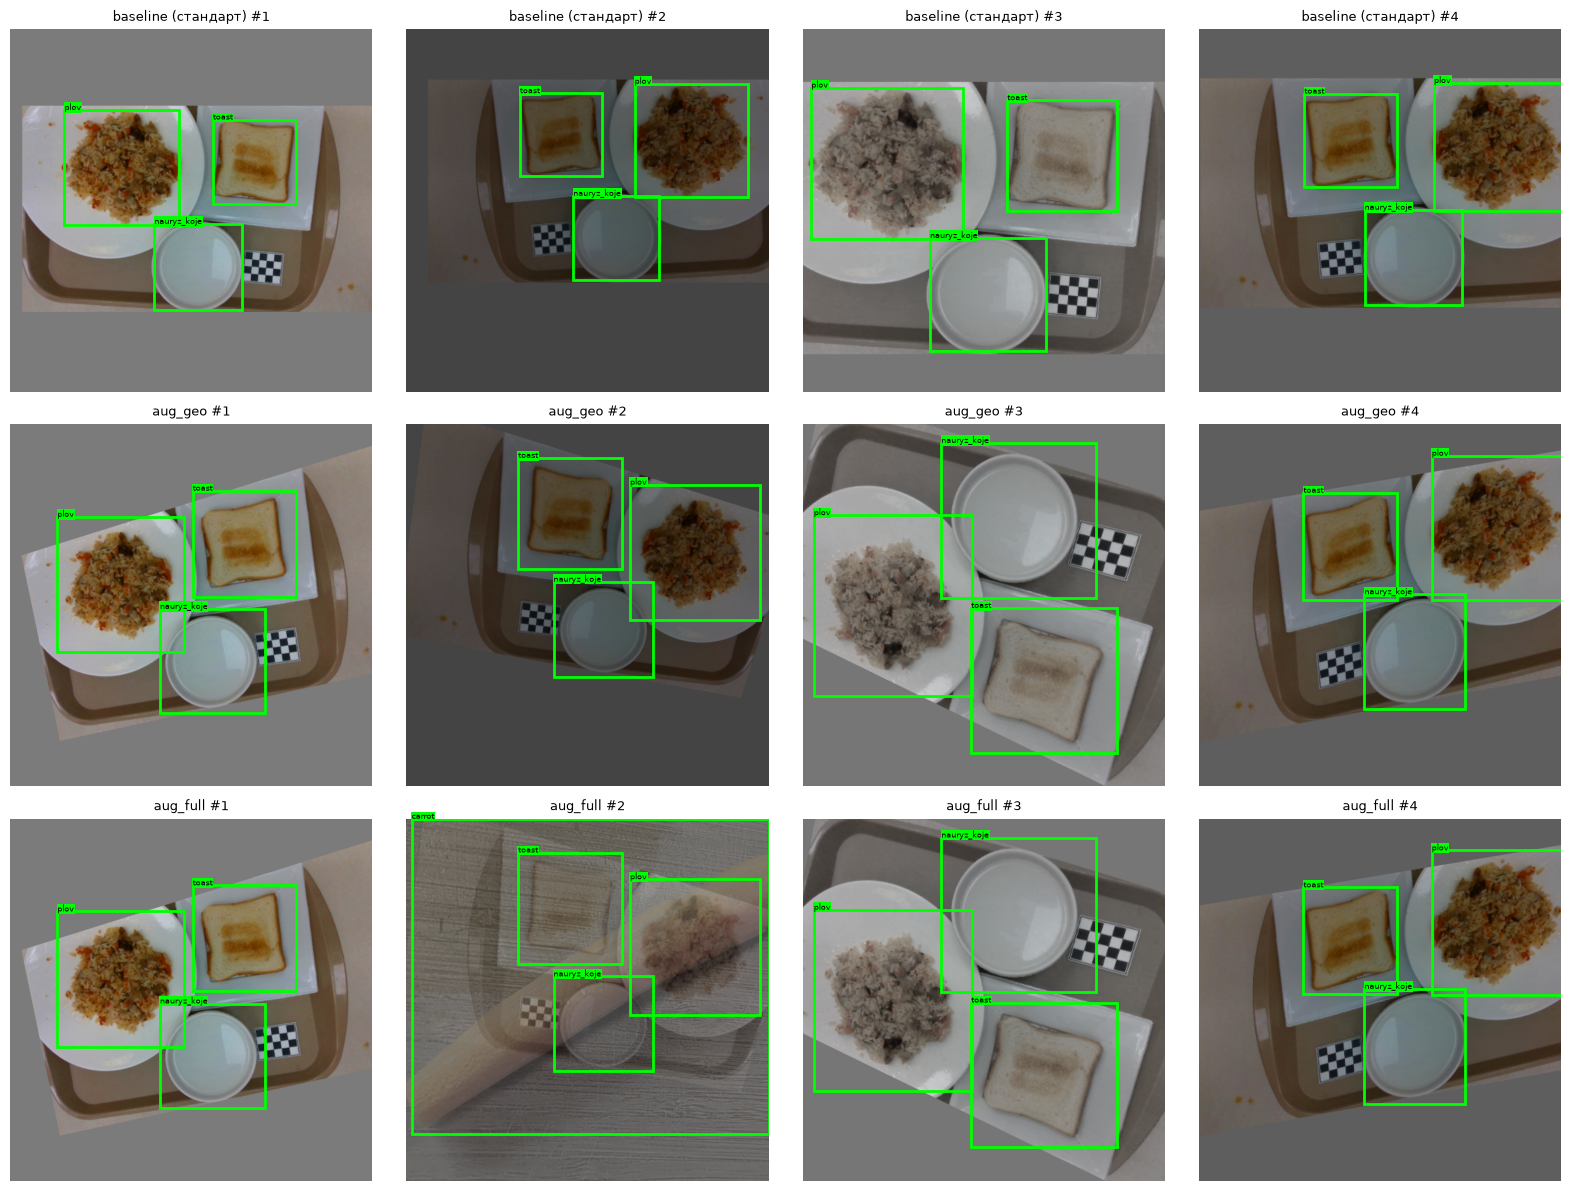

In [9]:
def draw(ax, item, title):
    img = item['img'].permute(1, 2, 0).numpy()          # RGB, uint8
    h, w = img.shape[:2]
    ax.imshow(img)
    for (x, y, bw, bh), c in zip(item['bboxes'].numpy(), item['cls'].numpy().ravel()):
        x0, y0 = (x - bw / 2) * w, (y - bh / 2) * h
        ax.add_patch(plt.Rectangle((x0, y0), bw * w, bh * h, fill=False, lw=2, ec='lime'))
        ax.text(x0, y0, class_name(int(c)), fontsize=6, color='black',
                bbox=dict(fc='lime', pad=0.5, lw=0))
    ax.set_title(title, fontsize=9); ax.axis('off')

N_COLS = 4
fig, axes = plt.subplots(len(PREVIEW_VARIANTS), N_COLS,
                         figsize=(4 * N_COLS, 4 * len(PREVIEW_VARIANTS)), squeeze=False)
for row, (variant, extra) in enumerate(PREVIEW_VARIANTS.items()):
    ds = make_dataset(extra)
    for col in range(N_COLS):
        random.seed(col); np.random.seed(col); torch.manual_seed(col)
        draw(axes[row, col], ds[PREVIEW_IDX], f'{variant} #{col + 1}')
plt.tight_layout(); plt.show(); plt.close(fig)

In [5]:
BASELINE_DIR = next((ROOT / 'models').glob('food_yolo11n_2*'))
baseline = pd.read_csv(BASELINE_DIR / 'metrics.csv', index_col='split')
display(baseline.round(5))

,precision,recall,mAP50,mAP50-95
split,,,,
val,0.00438,0.13318,0.00679,0.00523
test,0.00596,0.12905,0.00843,0.00666


## Обучение и оценка двух вариантов

In [11]:
train_dirs = {}      # variant -> каталог обучения
train_time = {}      # variant -> секунды

for variant, extra in AUG_VARIANTS.items():
    print(f'\n=== {variant}: {extra} ===')
    t0 = time.time()
    model = YOLO(str(INITIAL_WEIGHTS))               # тот же старт: COCO-веса
    res = model.train(project=str(RUN_DIR), name=variant, **COMMON, **extra)
    train_dirs[variant] = Path(res.save_dir)
    train_time[variant] = time.time() - t0
    print(f'{variant}: готово за {train_time[variant] / 60:.1f} мин -> {train_dirs[variant]}')


=== aug_geo: {'degrees': 25.0, 'flipud': 0.3, 'shear': 5.0, 'perspective': 0.0005} ===
New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.228 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/runs/yolo11n_aug_20261110_204105_214743/data.yaml, degrees=25.0, deterministic=True, device=mps, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.3, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, 

/Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/1       5.3G      1.376      5.645      1.775         20        640: 100% ━━━━━━━━━━━━ 6544/6544 2.7it/s 40:09<0.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 614/614 2.6it/s 4:00<0.3s
                   all       9816      17604    0.00274      0.114    0.00483    0.00232

1 epochs completed in 0.737 hours.
Optimizer stripped from /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/runs/yolo11n_aug_20261110_204105_214743/aug_geo/weights/last.pt, 5.8MB
Optimizer stripped from /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/runs/yolo11n_aug_20261110_204105_214743/aug_geo/weights/best.pt, 5.8MB

Validating /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/runs/yolo11n_aug_20261110_204105_214743/aug_geo/weights/best.pt...
Ultralytics 8.3.228 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 100 layers, 2,743,639 parameters

/Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/1      5.25G      1.441       5.64       1.83         24        640: 100% ━━━━━━━━━━━━ 6544/6544 2.6it/s 41:55<0.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 614/614 2.6it/s 3:58<0.3s
                   all       9816      17604    0.00357      0.104    0.00499     0.0025

1 epochs completed in 0.766 hours.
Optimizer stripped from /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/runs/yolo11n_aug_20261110_204105_214743/aug_full/weights/last.pt, 5.8MB
Optimizer stripped from /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/runs/yolo11n_aug_20261110_204105_214743/aug_full/weights/best.pt, 5.8MB

Validating /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/runs/yolo11n_aug_20261110_204105_214743/aug_full/weights/best.pt...
Ultralytics 8.3.228 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 100 layers, 2,743,639 paramet

In [12]:
rows, eval_reports = [], {}
for variant, tdir in train_dirs.items():
    weights = tdir / 'weights/best.pt'
    m = YOLO(str(weights))
    for split in ('val', 'test'):
        r = m.val(data=str(RUNTIME_YAML), split=split, imgsz=IMAGE_SIZE, batch=BATCH,
                  workers=WORKERS, device=DEVICE, project=str(RUN_DIR),
                  name=f'eval_{variant}_{split}', exist_ok=False, plots=False)
        eval_reports[(variant, split)] = r
        rows.append(dict(variant=variant, split=split, precision=float(r.box.mp),
                         recall=float(r.box.mr), mAP50=float(r.box.map50),
                         **{'mAP50-95': float(r.box.map)}))

aug_summary = pd.DataFrame(rows)

# добавляем строки исходного бейзлайна (из metrics.csv)
base_rows = baseline.reset_index().rename(columns={'index': 'split'})
base_rows.insert(0, 'variant', 'baseline')
comparison = pd.concat([base_rows, aug_summary], ignore_index=True)
comparison = comparison.sort_values(['split', 'variant']).reset_index(drop=True)
display(comparison.round(5))

Ultralytics 8.3.228 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 100 layers, 2,743,639 parameters, 0 gradients, 7.2 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 274.8±188.6 MB/s, size: 65.6 KB)
val: Scanning /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/processed/fpb_myfoodrepo_full/labels/val.cache... 9816 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 9816/9816 16.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1227/1227 12.4it/s 1:39<0.2s
                   all       9816      17604    0.00274      0.114    0.00481    0.00232
              achichuk         15         15    0.00061     0.0667   0.000327   0.000163
                almond         75         76    0.00054     0.0132   0.000275    0.00011
           apple_juice         28         28    0.00394      0.393     0.0033    0.00193
         apple_strudel         23         24    0.006

,variant,split,precision,recall,mAP50,mAP50-95
0,aug_full,test,0.00385,0.10132,0.00571,0.00278
1,aug_geo,test,0.00292,0.11054,0.00595,0.00279
2,baseline,test,0.00596,0.12905,0.00843,0.00666
3,aug_full,val,0.00356,0.10339,0.00498,0.00250
4,aug_geo,val,0.00274,0.11417,0.00481,0.00232
5,baseline,val,0.00438,0.13318,0.00679,0.00523


In [13]:
comparison.round(5)

,variant,split,precision,recall,mAP50,mAP50-95
0,aug_full,test,0.00385,0.10132,0.00571,0.00278
1,aug_geo,test,0.00292,0.11054,0.00595,0.00279
2,baseline,test,0.00596,0.12905,0.00843,0.00666
3,aug_full,val,0.00356,0.10339,0.00498,0.00250
4,aug_geo,val,0.00274,0.11417,0.00481,0.00232
5,baseline,val,0.00438,0.13318,0.00679,0.00523


## Проверка и оформление выводов

precision  recall   mAP50  mAP50-95  ratio_95_50
split variant                                                   
test  aug_full     0.0038  0.1013  0.0057    0.0028       0.4869
      aug_geo      0.0029  0.1105  0.0060    0.0028       0.4681
      baseline     0.0060  0.1290  0.0084    0.0067       0.7897
val   aug_full     0.0036  0.1034  0.0050    0.0025       0.5017
      aug_geo      0.0027  0.1142  0.0048    0.0023       0.4834
      baseline     0.0044  0.1332  0.0068    0.0052       0.7704

val  aug_geo   mAP50 -29% | mAP50-95 -56%
val  aug_full  mAP50 -27% | mAP50-95 -52%
test aug_geo   mAP50 -29% | mAP50-95 -58%
test aug_full  mAP50 -32% | mAP50-95 -58%


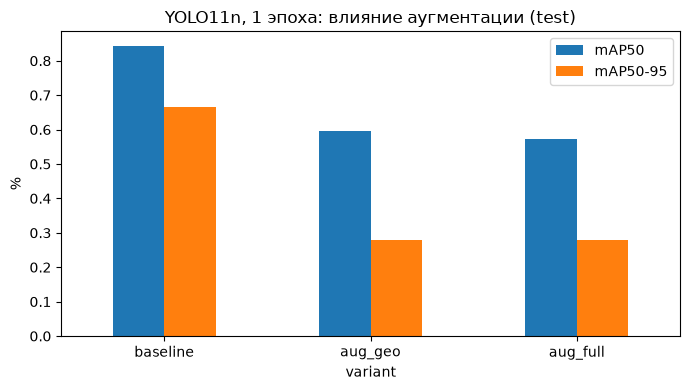

Ultralytics 8.3.228 🚀 Python-3.12.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 100 layers, 2,743,639 parameters, 0 gradients, 7.2 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 965.3±948.9 MB/s, size: 566.7 KB)
val: Scanning /Users/g.abdukhalikov/Desktop/Мага/Годовой проект/v2/calorie_diary/data/processed/fpb_myfoodrepo_full/labels/test.cache... 3272 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3272/3272 10.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 409/409 12.7it/s 32.2s0.2ss
                   all       3272       5865    0.00596      0.129    0.00843    0.00666
              achichuk          7          7          0          0          0          0
                almond         19         19          0          0          0          0
           apple_juice          8          8    0.00201       0.25    0.00256     0.0022
         apple_strudel         11         11    0.00

In [14]:
cmp = comparison.set_index(['split', 'variant'])
cmp['ratio_95_50'] = cmp['mAP50-95'] / cmp['mAP50']
display(cmp.round(4))

# Относительное изменение к baseline
for split in ('val', 'test'):
    for v in AUG_VARIANTS:
        d50 = cmp.loc[(split, v), 'mAP50'] / cmp.loc[(split, 'baseline'), 'mAP50'] - 1
        d95 = cmp.loc[(split, v), 'mAP50-95'] / cmp.loc[(split, 'baseline'), 'mAP50-95'] - 1
        print(f'{split:4s} {v:9s} mAP50 {d50:+.0%} | mAP50-95 {d95:+.0%}')

# График на test
t = cmp.xs('test', level='split')[['mAP50', 'mAP50-95']] * 100
t.loc[['baseline', 'aug_geo', 'aug_full']].plot.bar(figsize=(7, 4), rot=0)
plt.ylabel('%'); plt.title('YOLO11n, 1 эпоха: влияние аугментации (test)')
plt.tight_layout(); plt.show()

# Сколько классов модель реально находит (test)
base_model = YOLO(str(BASELINE_DIR / 'best.pt'))
rb = base_model.val(data=str(RUNTIME_YAML), split='test', imgsz=IMAGE_SIZE, batch=BATCH,
                    workers=WORKERS, device=DEVICE, project=str(RUN_DIR),
                    name='eval_baseline_test', exist_ok=False, plots=False)
reports = {'baseline': rb, **{v: eval_reports[(v, 'test')] for v in AUG_VARIANTS}}
for v, r in reports.items():
    print(f'{v:9s} классов с AP50>0: {int((r.box.ap50 > 0).sum())} из {len(r.box.ap50)}')

Мы применили к бейзлайну YOLO11n (1 эпоха, те же данные, seed=42) две конфигурации расширенной аугментации поверх стандартной: 
* **aug_geo** (повороты ±25°, вертикальный флип, shear, perspective);
* **aug_full** (то же + mixup и небольшой сдвиг оттенка). 

Обе дали ухудшение метрик на `val` и на `test`: 
* **mAP50** на test упал с 0,84% до 0,60% и 0,57%;
* **mAP50–95** — с 0,67% до 0,28%. 

Число классов с ненулевым AP50 снизилось с 162 до 148 и 146 из 413. Разница между **aug_geo** и **aug_full** незначительна, то есть mixup и цветовые изменения ничего не добавили. Причина, вероятно, в том, что за одну эпоху модель успевает сделать мало шагов обучения, и усложнённые примеры только замедляют сходимость; аугментация защищает от переобучения, а переобучения на первой эпохе ещё нет. Более сильное падение **mAP50–95** может говорить о снижении точности границ рамок (при повороте рамки расширяются), но на этом этапе это гипотеза. 

**Практический вывод:** на столь коротком обучении расширять аугментацию не нужно; вопрос о её пользе остаётся открытым и требует более длинного обучения (десятки эпох), где проявляется переобучение.

## Сохранение весов

In [16]:
EXPORT_DIR.mkdir(parents=True, exist_ok=False)

for variant, tdir in train_dirs.items():
    shutil.copy2(tdir / 'weights/best.pt', EXPORT_DIR / f'{variant}_best.pt')

comparison.round(5).to_csv(EXPORT_DIR / 'comparison.csv', index=False)

(EXPORT_DIR / 'run.json').write_text(json.dumps({
    'base_model': 'yolo11n (COCO init)',
    'epochs': EPOCHS, 'imgsz': IMAGE_SIZE, 'batch': BATCH, 'seed': SEED,
    'variants': AUG_VARIANTS,
    'train_minutes': {v: round(s / 60, 1) for v, s in train_time.items()},
}, ensure_ascii=False, indent=2))

print(sorted(p.name for p in EXPORT_DIR.iterdir()))

['aug_full_best.pt', 'aug_geo_best.pt', 'comparison.csv', 'run.json']
